In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv("/kaggle/input/datasets/erkanturgut/steel-industry-energy-consumption-data/Steel_industry_data.csv")

In [3]:
df.head()

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


In [4]:
df.isnull().sum()

date                                    0
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
CO2(tCO2)                               0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

In [5]:
print(f"Shape: {df.shape}")

Shape: (35040, 11)


In [6]:
print(f"Data Types: {df.dtypes}")

Data Types: date                                     object
Usage_kWh                               float64
Lagging_Current_Reactive.Power_kVarh    float64
Leading_Current_Reactive_Power_kVarh    float64
CO2(tCO2)                               float64
Lagging_Current_Power_Factor            float64
Leading_Current_Power_Factor            float64
NSM                                       int64
WeekStatus                               object
Day_of_week                              object
Load_Type                                object
dtype: object


In [7]:
display(df.describe())

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000,35040.000000
mean,27.386892,13.035384,3.870949,0.011524,80.578056,84.367870,42750.000000
std,33.444380,16.306000,7.424463,0.016151,18.921322,30.456535,24940.534317
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.200000,2.300000,0.000000,0.000000,63.320000,99.700000,21375.000000
50%,4.570000,5.000000,0.000000,0.000000,87.960000,100.000000,42750.000000
75%,51.237500,22.640000,2.090000,0.020000,99.022500,100.000000,64125.000000
max,157.180000,96.910000,27.760000,0.070000,100.000000,100.000000,85500.000000


In [8]:
# distribution of categorical variables
print("\nWeekStatus value counts:")
print(df['WeekStatus'].value_counts())


WeekStatus value counts:
WeekStatus
Weekday    25056
Weekend     9984
Name: count, dtype: int64


In [9]:
print("\nDay_of_week value counts:")
print(df['Day_of_week'].value_counts())


Day_of_week value counts:
Day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992
Name: count, dtype: int64


In [10]:
print("Load_Type value counts:\n")
print(df['Load_Type'].value_counts())

Load_Type value counts:

Load_Type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


Text(0.5, 1.0, 'Usage_kWh Distribution')

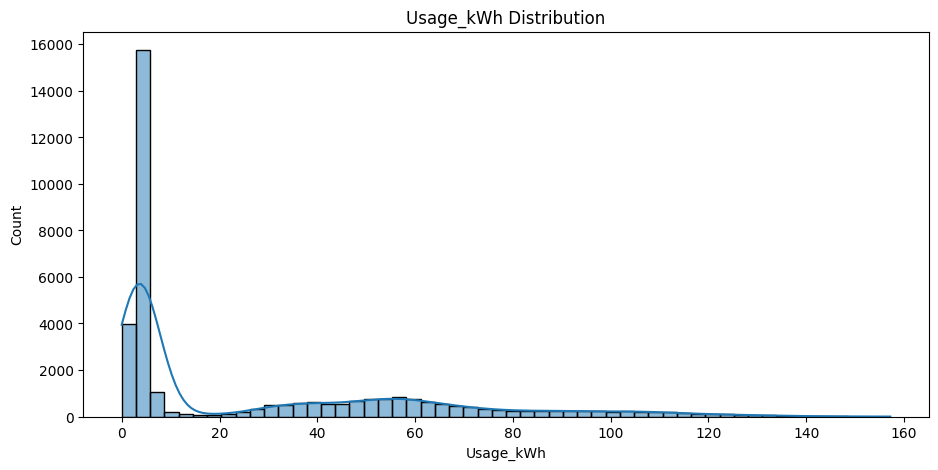

In [11]:
#Analysis of the Target Variable
import matplotlib.pyplot as plt
import seaborn as sns


plt.figure(figsize=(24,5))
plt.subplot(1, 2, 1)

sns.histplot(df['Usage_kWh'], kde=True)
plt.title('Usage_kWh Distribution')

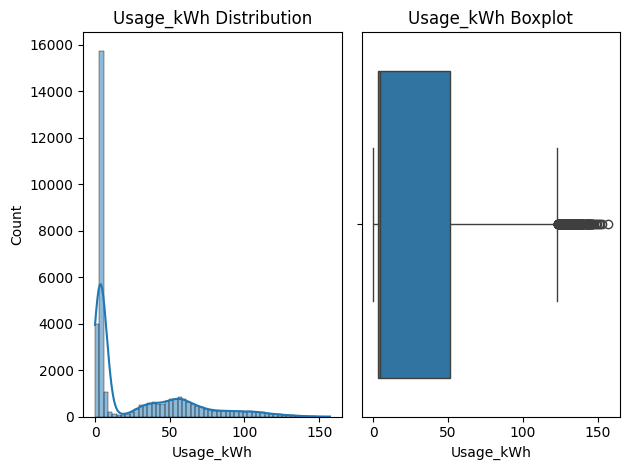

Skewness: 1.197393822769221


In [12]:
plt.subplot(1, 2, 1)
sns.histplot(df['Usage_kWh'], kde=True)
plt.title('Usage_kWh Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(x=df['Usage_kWh'])
plt.title('Usage_kWh Boxplot')

plt.tight_layout()
plt.show()

print("Skewness:", df['Usage_kWh'].skew())

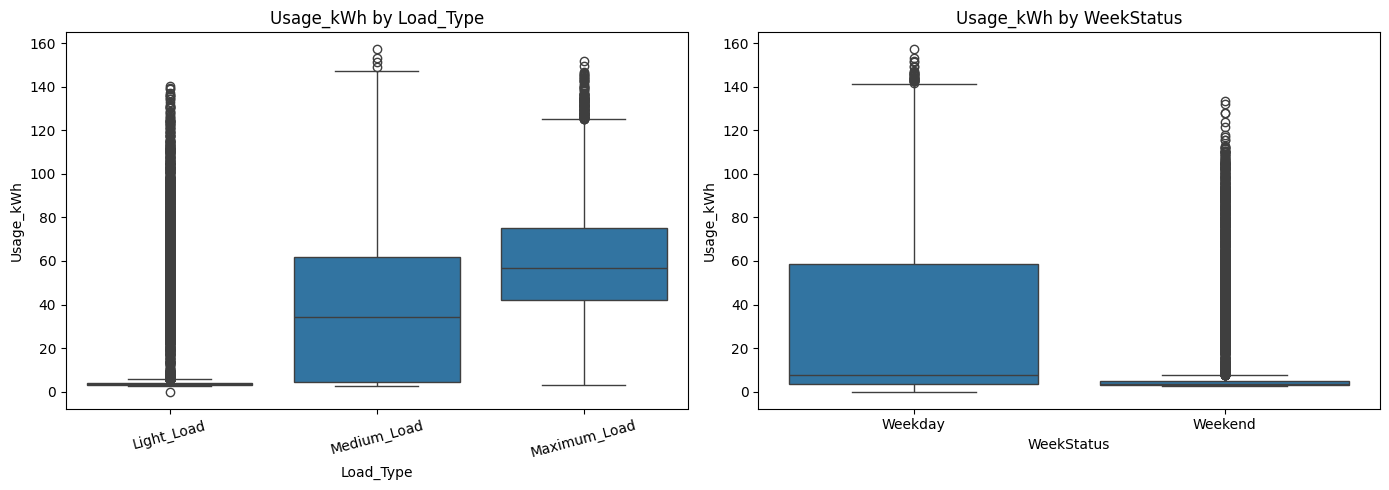

In [13]:
# Categorical vs. Target Relationship
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
sns.boxplot(data = df , x="Load_Type", y="Usage_kWh")
plt.title("Usage_kWh by Load_Type")
plt.xticks(rotation=15)


plt.subplot(1,2,2)
sns.boxplot(data=df, x='WeekStatus', y="Usage_kWh")
plt.title("Usage_kWh by WeekStatus")

plt.tight_layout()
plt.show()

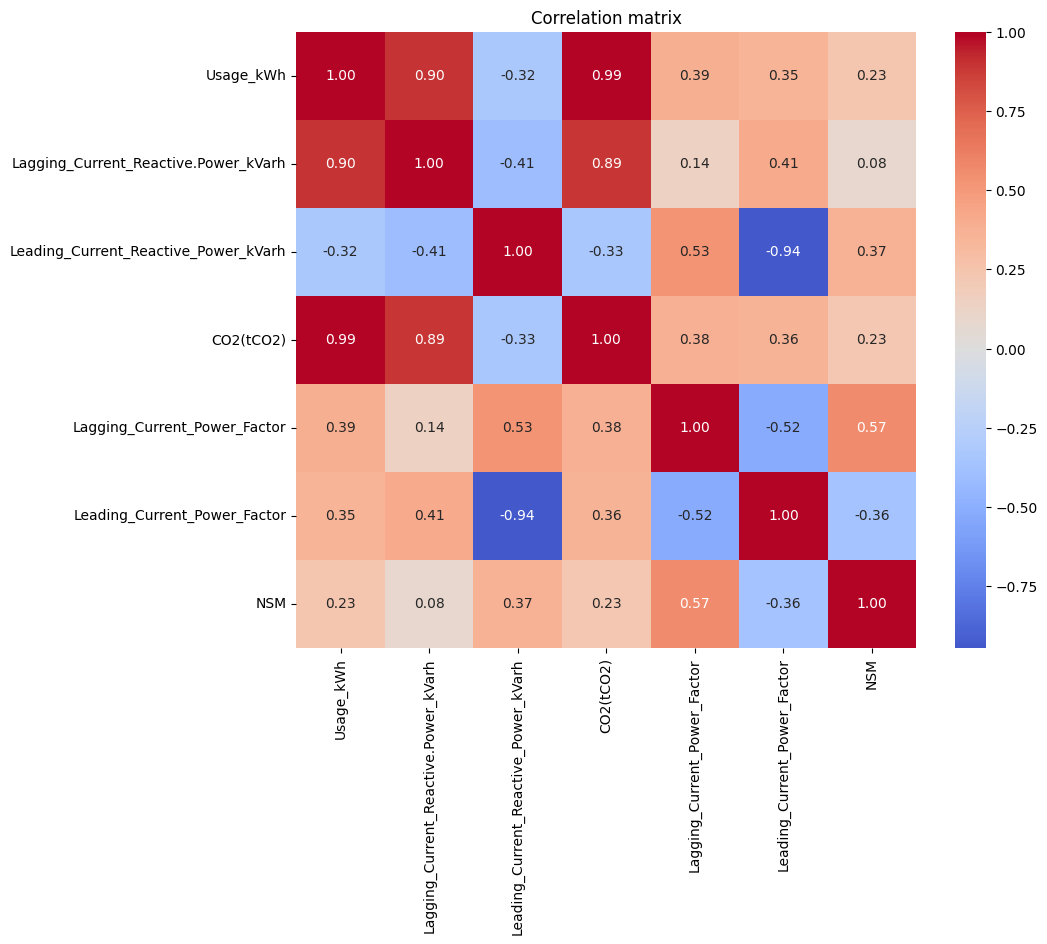

In [14]:
# correlation of numerical variables

numeric_cols = df.select_dtypes(include = ["float64", "int64"]).columns
plt.figure(figsize = (10,8))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center =0)
plt.title("Correlation matrix")
plt.show()

the most critical point:

there is a 0.99 correlation between **CO2(tCO2)** and **Usage_kWh** 

This is almost a perfect relationship. Most likely CO2, derived from energy consumption or is very directly linked to it. If we include this feature in the model, the **data leakege risk is too high** and the model produces abssurdly good results(which aren't realistic)

| Subject | Decision | Explanation |
| --- | --- | --- |
| CO2(tCO2) | Remove from model | 0.99 correlation → leakage risk |
| Outlier | keep it for now, evaluate it later | less than %1 |
| target skewness | the log transformation will be tested | Skewness 1.20 |
| Load_Type & WeekStatus | must be used | there is a strong signal |
| Lagging Reactive Power | to be used | 0.90 correlation |

In [15]:
# see how many outliers there are using the IQR
Q1 = df["Usage_kWh"].quantile(0.25)
Q3 = df["Usage_kWh"].quantile(0.75)

IQR = Q3 -Q1
outliers = df[(df["Usage_kWh"] < Q1 - 1.5*IQR) | (df['Usage_kWh'] > Q3 + 1.5*IQR)]
print(f"Outlier sayısı : {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")

Outlier sayısı : 328 (0.9%)


In [16]:
# remowe co2(leakage risk)
df_clean = df.drop(columns = ["CO2(tCO2)", "date"]) # also date for now

print(df_clean.columns.to_list())
print(f"\nShape: {df_clean.shape}")

['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus', 'Day_of_week', 'Load_Type']

Shape: (35040, 9)


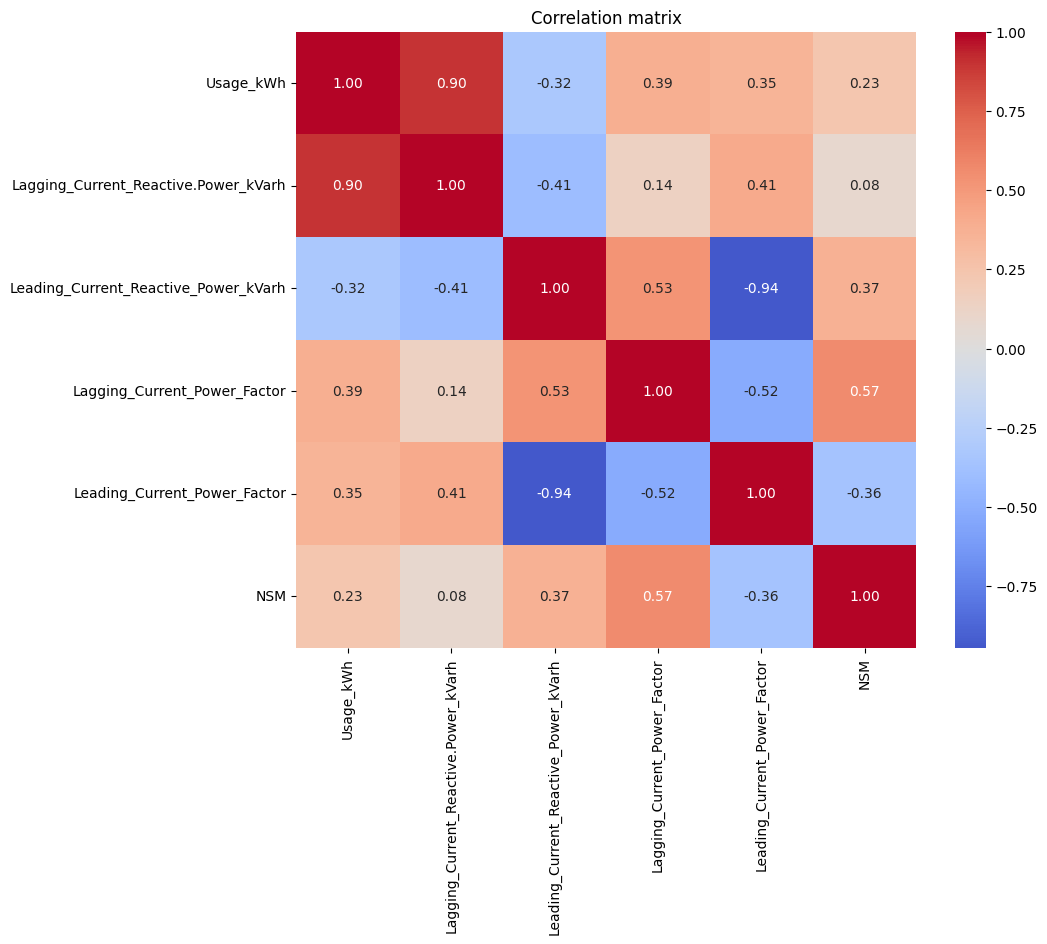

In [17]:
# correlation of numerical variables

numeric_cols = df_clean.select_dtypes(include = ["float64", "int64"]).columns
plt.figure(figsize = (10,8))
sns.heatmap(df_clean[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center =0)
plt.title("Correlation matrix")
plt.show()

In [18]:
#MAKE A BASIC TRAIN TEST SPLIT(JUST PREPARATION)

from sklearn.model_selection import train_test_split
X = df_clean.drop(columns = ["Usage_kWh"]) # infos the model will see
y = df_clean["Usage_kWh"]  # what the model will try to predict

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state =42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# X -> model inputs(features/independent variables)
# y -> model's target(dependent variable)
# We are trying to predict the Usage_kWh value (the model will take the other columns into account to predict the Usage_kWh value)
# if we also  include the Usage_kWh value in X, the model will already be able to predict the outcome in this case; in this scenario, the model will easily memorize the outcome, resulting in data leakage

X_train: (28032, 8)
X_test : (7008, 8)
y_train: (28032,)
y_test : (7008,)


In [19]:
# Eksik değer ve split kontrolü
print("Eksik değerler:")
print(df_clean.isnull().sum())
print("\nToplam eksik:", df_clean.isnull().sum().sum())

Eksik değerler:
Usage_kWh                               0
Lagging_Current_Reactive.Power_kVarh    0
Leading_Current_Reactive_Power_kVarh    0
Lagging_Current_Power_Factor            0
Leading_Current_Power_Factor            0
NSM                                     0
WeekStatus                              0
Day_of_week                             0
Load_Type                               0
dtype: int64

Toplam eksik: 0


In [20]:
#  One-Hot Encoding (train'den öğren, test'e uygula)
cat_cols = ['WeekStatus', 'Day_of_week', 'Load_Type']

# Sadece train'den dummy üret
X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

# Test'i train'in sütun setine hizala
# (test'te görülmeyen kategori olursa 0 ile doldurulur)
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print("X_train_encoded shape:", X_train_encoded.shape)
print("X_test_encoded shape :", X_test_encoded.shape)
print("\nSütunlar:")
print(X_train_encoded.columns.tolist())

X_train_encoded shape: (28032, 14)
X_test_encoded shape : (7008, 14)

Sütunlar:
['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM', 'WeekStatus_Weekend', 'Day_of_week_Monday', 'Day_of_week_Saturday', 'Day_of_week_Sunday', 'Day_of_week_Thursday', 'Day_of_week_Tuesday', 'Day_of_week_Wednesday', 'Load_Type_Maximum_Load', 'Load_Type_Medium_Load']


In [21]:
X_train_encoded.head()

,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus_Weekend,Day_of_week_Monday,Day_of_week_Saturday,Day_of_week_Sunday,Day_of_week_Thursday,Day_of_week_Tuesday,Day_of_week_Wednesday,Load_Type_Maximum_Load,Load_Type_Medium_Load
9284,0.00,21.78,100.00,18.85,62100,True,False,True,False,False,False,False,False,True
14314,4.93,0.00,50.96,100.00,9900,False,False,False,False,False,False,True,False,False
5094,7.34,0.00,65.95,100.00,6300,False,False,False,False,False,False,False,False,False
33269,22.28,0.00,93.12,100.00,48600,False,False,False,False,True,False,False,False,True
9994,3.82,0.00,63.01,100.00,9900,True,False,False,True,False,False,False,False,False


In [22]:
# YENİ — Encoding sonrası sütun tiplerini kontrol et
print("Kalan object sütunlar:")
print(X_train_encoded.select_dtypes(include='object').columns.tolist())

print("\nSütun tipleri:")
print(X_train_encoded.dtypes.value_counts())

Kalan object sütunlar:
[]

Sütun tipleri:
bool       9
float64    4
int64      1
Name: count, dtype: int64


In [23]:
from sklearn.preprocessing import StandardScaler
#1) creae scalr 
scaler = StandardScaler()
#2) just fit the train data
scaler.fit(X_train_encoded)
#3) convert training  and tet data to the same format
X_train_scaled = scaler.transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape :", X_test_scaled.shape)

X_train_scaled shape: (28032, 14)
X_test_scaled shape : (7008, 14)


In [24]:
type(X_train_scaled)

numpy.ndarray

In [25]:
# convert numpy array to dataframe
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns = X_train_encoded.columns, index = X_train_encoded.index)

X_test_scaled_df = pd.DataFrame(X_test_scaled, columns = X_test_encoded.columns, index= X_test_encoded.index)

# look at the first 3 rows
X_train_scaled_df.head(3)

,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus_Weekend,Day_of_week_Monday,Day_of_week_Saturday,Day_of_week_Sunday,Day_of_week_Thursday,Day_of_week_Tuesday,Day_of_week_Wednesday,Load_Type_Maximum_Load,Load_Type_Medium_Load
9284,-0.798509,2.404457,1.027010,-2.147693,0.781171,1.582126,-0.413493,2.448624,-0.407679,-0.404639,-0.406726,-0.408987,-0.50927,1.616427
14314,-0.495515,-0.522458,-1.563027,0.513680,-1.314120,-0.632061,-0.413493,-0.408393,-0.407679,-0.404639,-0.406726,2.445065,-0.50927,-0.618648
5094,-0.347399,-0.522458,-0.771334,0.513680,-1.458623,-0.632061,-0.413493,-0.408393,-0.407679,-0.404639,-0.406726,-0.408987,-0.50927,-0.618648


In [26]:
from sklearn.linear_model import LinearRegression
# let's train first baseline model
#1) create model
lr_model = LinearRegression()

#2) train
lr_model.fit(X_train_scaled_df, y_train)

#3) predict on test data
y_pred = lr_model.predict(X_test_scaled_df)

print("The model has been trained and predictions have been made")
print("First 5 real values : ", y_test.values[:5])
print("First 5 prediction values", y_pred[:5])

The model has been trained and predictions have been made
First 5 real values :  [  2.88  60.77 120.42   3.13  58.86]
First 5 prediction values [  3.64347513  83.78103794 107.44479439  -1.52500105  55.54992683]


In [27]:
# metrics(Measure the success)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse=np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Linear Regression Baseline Results ---")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"MSE  (Mean Squared Error)   : {mse:.4f}")
print(f"RMSE (Root Mean Square Error): {rmse:.4f}")
print(f"R²   (Explained Variance)    : {r2:.4f}")

--- Linear Regression Baseline Results ---
MAE  (Mean Absolute Error) : 7.0203
MSE  (Mean Squared Error)   : 95.8709
RMSE (Root Mean Square Error): 9.7914
R²   (Explained Variance)    : 0.9157


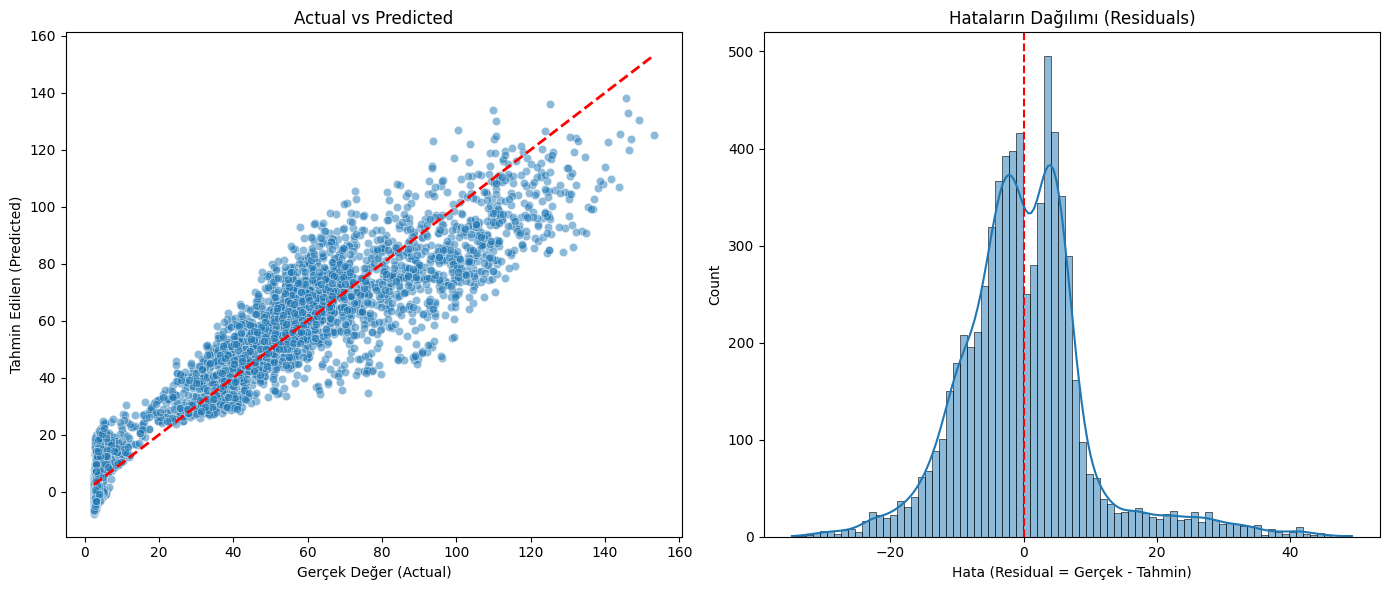

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Actual vs Predicted Graphic
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.5)
# best preiction line ( red)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Gerçek Değer (Actual)")
plt.ylabel("Tahmin Edilen (Predicted)")
plt.title("Actual vs Predicted")

# 2. Residual (Hata) distribution
residuals = y_test - y_pred

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True, bins=80)
plt.axvline(x=0, color='r', linestyle='--')
plt.xlabel("Hata (Residual = Gerçek - Tahmin)")
plt.title("Hataların Dağılımı (Residuals)")

plt.tight_layout()
plt.show()

In [29]:
# Naive Baseline ( just preict mean of train)
naive_pred = [y_train.mean()] * len(y_test)

naive_mae = mean_absolute_error(y_test, naive_pred)
naive_rmse = np.sqrt(mean_squared_error(y_test, naive_pred))
naive_r2 = r2_score(y_test, naive_pred)

print("--- Naive Baseline (Ortalama Tahmini) ---")
print(f"MAE : {naive_mae:.4f}")
print(f"RMSE: {naive_rmse:.4f}")
print(f"R²  : {naive_r2:.4f}")

--- Naive Baseline (Ortalama Tahmini) ---
MAE : 28.8016
RMSE: 33.7191
R²  : -0.0002


In [30]:
# setup PIPELINE
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression


# 1. specify the categorical and numerical columns(on the X_train)
numeric_features = ['Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh', 
                    'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'NSM']


categorical_features = [
    "WeekStatus","Day_of_week","Load_Type"
]

# 2. Processing Numeric Data(StandardScaler Only)
numeric_transformer = Pipeline(steps =[
    ("scaler", StandardScaler())
])

# 3. Processing categorical data(OneHOtEncoder)
# drop = 'first'  prevents the "dummy variable trap" and handle=unknown = "ignore" prenvents an error from occuring if a new category appears in the test
categorical_transformer = Pipeline(steps = [
    ("onehot", OneHotEncoder(drop = "first", handle_unknown ='ignore'))
])


# 4. use ColumnTransfer to combine both of them 
preprocessor = ColumnTransformer(
    transformers = [
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 5. group allseries into a single PIPELINE
pipeline_lr = Pipeline(steps=[
    ("preprocessor",preprocessor),
    ("regressor", LinearRegression())
])

# 6. Train using the raw X_train and y_train data (it will handle the encoding and scaling for us)
pipeline_lr.fit(X_train, y_train)

# 7. Predict with test data
y_pred_pipeline = pipeline_lr.predict(X_test)

# Compare the results
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
rmse_pipeline = np.sqrt(mean_squared_error(y_test, y_pred_pipeline))
r2_pipeline = r2_score(y_test, y_pred_pipeline)

print(f"Pipeline RMSE: {rmse_pipeline:.4f}")
print(f"Pipeline R2: {r2_pipeline:.4f}")

Pipeline RMSE: 9.7914
Pipeline R2: 0.9157


In [31]:
# do a 5 level corss validaiton
#since we are using a pipeline, CV fits the scaler and encoder from scratch in every fold, only on the train portion of that fold.(No data leakage)

#cv_scores_r2 = cross_val_score(pipeline_lr, X_train, y_train, cv =5, scoring = "r2")
#cv_scores_rmse